# Roteiro 8 - Regressão Logística

Este é o roteiro da oitava aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

Esse documento mostra um exemplo de classificação via regressão logística.

O roteiro contém:

1.   Implementação da função sigmoid
2.   Implementação da função de custo $J(\theta)$
3.   Exemplo de aprendizado de parâmetros $\theta$
4.   Visualização da Superfície de decisão
5.   Avaliação e Cálculo da acurácia
6.   Comparação com a regressão logística do pacote `Sciki-Learn`
7.   Exercício valendo **2,5 pontos** sobre classificação não-liear


---


Autor: raoni.teixeira@ufmt.br

# 1. Regressão Logística


Nessa parte da aula, você irá implementar um sistema de diagnóstico médico que  classifica pacientes como saudáveis ou doentes levando em conta duas variáveis reais obtidas de exames: `exame_1` e `exame_2`.


## 1.1 Baixando os dados

In [ ]:
!gdown '1Zp5jwkCX-jD53PMCjX09pG_KeQ8mWbRh'

Downloading...
From: https://drive.google.com/uc?id=1Zp5jwkCX-jD53PMCjX09pG_KeQ8mWbRh
To: /content/data1.txt
100% 3.77k/3.77k [00:00<00:00, 11.0MB/s]


## 1.2 *Carregando* as bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

## 1.3 Lendo e Visualizando os dados


In [ ]:
df = pd.read_csv('data1.txt', sep=',', header=None)
df.columns = ['exame_1', 'exame_2', 'classe']

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
exame_1,100.0,65.644274,19.458222,30.058822,50.919511,67.032988,80.212529,99.827858
exame_2,100.0,66.221998,18.582783,30.603263,48.179205,67.682381,79.360605,98.869436
classe,100.0,0.600000,0.492366,0.000000,0.000000,1.000000,1.000000,1.000000


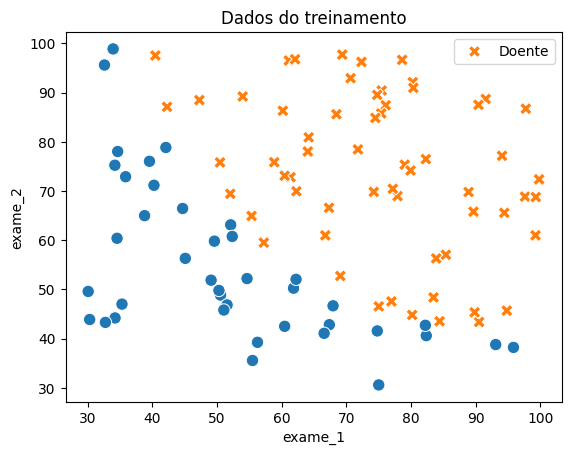

In [ ]:
#plt.figure(figsize=(7,5))
ax = sns.scatterplot(x='exame_1', y='exame_2', hue='classe', data=df, style='classe', s=80)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[1:], ['Doente', 'Saudável'])
plt.title('Dados do treinamento')
plt.show(ax)

## 1.4 Implementação



### 1.4.1 Função Sigmoid

A hipótese é definida da seguinte forma:

$$h_\theta(x) = g(\theta^Tx)$$

$$g(z) = \frac{1}{1+e^{-z}}$$

In [ ]:
def sigmoid(z):
    z = np.array(z)
    return 1 / (1+np.exp(-z))

O gráfico da função é dado por:

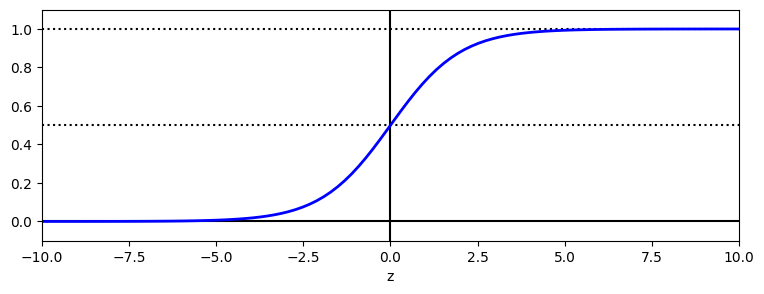

In [ ]:
%matplotlib inline
z = np.linspace(-10, 10, 100)
sig = sigmoid(z)
plt.figure(figsize=(9, 3))
plt.plot([-10, 10], [0, 0], "k-")
plt.plot([-10, 10], [0.5, 0.5], "k:")
plt.plot([-10, 10], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(z, sig, "b-", linewidth=2)
plt.xlabel("z")
plt.axis([-10, 10, -0.1, 1.1])
plt.show()

### 1.4.2 Função de Custo e Gradiente


A função de custo é dada por:

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^m[y^i log(h_\theta(x^i))+(1-y^i)log(1-h_\theta(x^i))]$$

A implementação vetorizada é dada por:

$h = g(X\theta)$

$J(\theta) = \frac{1}{m}(-y^T log(h)-(1-y)^Tlog(1-h))$



O vetor gradinte da função $J$ tem o mesmo tamanho de $\theta$ e cada elemento  $j^{th}$  (para $j=0,1,...,n$) é definido da seguinte forma:

$$\nabla J(\theta) = \frac{1}{m} \sum_{i=1}^m ((h_\theta(x^i) - y^i) \cdot x_j^i)$$

A implementação vetorizada é dada por:
$\nabla J(\theta) = \frac{1}{m} \cdot X^T \cdot (g(X\theta)-y)$

In [ ]:
def cost_function(theta, X, y):
    m = y.shape[0]
    theta = theta[:, np.newaxis] #trick to make numpy minimize work
    h = sigmoid(X.dot(theta))
    J = (1/m) * (-y.T.dot(np.log(h)) - (1-y).T.dot(np.log(1-h)))

    diff_hy = h - y
    grad = (1/m) * diff_hy.T.dot(X)

    return J, grad

### 1.4.3 Teste da Implmentação

In [ ]:
m = df.shape[0]
X = np.hstack((np.ones((m,1)),df[['exame_1', 'exame_2']].values))
y = np.array(df.classe.values).reshape(-1,1)
initial_theta = np.zeros(shape=(X.shape[1]))

NameError: name 'df' is not defined

#### 1.4.3.1 Testes iniciais com valor iniial de  $\theta$


In [ ]:
cost, grad = cost_function(initial_theta, X, y)
print('Custo inicial (com theta  valendo zero):', cost)
print('Valor esperado do custo : 0.693')
print('Gradiente para theta zero:')
print(grad.T)
print('Valor esperado para o gradinte:\n -0.1000\n -12.0092\n -11.2628')

Custo inicial (com theta  valendo zero): [[0.69314718]]
Valor esperado do custo : 0.693
Gradiente para theta zero:
[[ -0.1       ]
 [-12.00921659]
 [-11.26284221]]
Valor esperado para o gradinte:
 -0.1000
 -12.0092
 -11.2628


#### 1.4.3.2 Teste com um valor específico de $\theta$

\begin{equation}
\theta = \begin{bmatrix} -24 \\
  0.2\\
 0.2\end{bmatrix}
 \end{equation}

In [ ]:
test_theta = np.array([-24, 0.2, 0.2])
[cost, grad] = cost_function(test_theta, X, y)

print('Custo:', cost)
print('Custo Esperado: 0.218')
print('Gradiente:')
print(grad.T)
print('Gradiente Esperado:\n 0.043\n 2.566\n 2.647')

Custo: [[0.21833019]]
Custo Esperado: 0.218
Gradiente:
[[0.04290299]
 [2.56623412]
 [2.64679737]]
Gradiente Esperado:
 0.043
 2.566
 2.647


# 1.5 Aprendendo os parâmetros usando um pacote de otimização

Usamos "Conjugate gradient", "BFGS", e "L-BFGS" do pacote `scipy`.

In [ ]:
import scipy.optimize as opt
def optimize_theta(X, y, initial_theta):
    opt_results = opt.minimize(cost_function, initial_theta, args=(X, y), method='TNC',
                               jac=True, options={'maxiter':400})
    return opt_results['x'], opt_results['fun']

In [ ]:
opt_theta, cost = optimize_theta(X, y, initial_theta)

<ipython-input-13-5ef08ad6c8bd>:3: OptimizeWarning: Unknown solver options: maxiter
  opt_results = opt.minimize(cost_function, initial_theta, args=(X, y), method='TNC',


In [ ]:
print('Custo para o theta encontrado pelo scipy:', cost)
print('Custo esperado: 0.203')
print('theta encontrado:\n', opt_theta.reshape(-1,1))
print('Theta esperado (approx):')
print(' -25.161\n 0.206\n 0.201')

Custo para o theta encontrado pelo scipy: 0.20349770158947478
Custo esperado: 0.203
theta encontrado:
 [[-25.16131857]
 [  0.20623159]
 [  0.20147149]]
Theta esperado (approx):
 -25.161
 0.206
 0.201


# 1.6  Superfície de Decisão

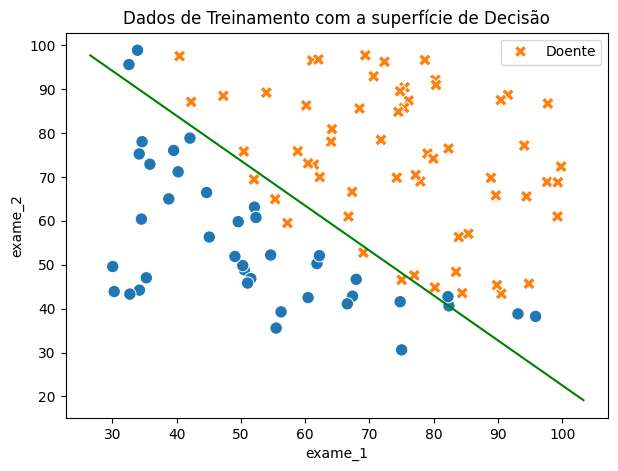

In [ ]:
plt.figure(figsize=(7,5))
ax = sns.scatterplot(x='exame_1', y='exame_2', hue='classe', data=df, style='classe', s=80)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[1:], ['Doente', 'Saudável'])
plt.title('Dados de Treinamento com a superfície de Decisão')

plot_x = np.array(ax.get_xlim())
plot_y = (-1/opt_theta[2]*(opt_theta[1]*plot_x + opt_theta[0]))
plt.plot(plot_x, plot_y, '-', c="green")
plt.show(ax)

# 1.7 Avaliando a Regressão Logística

### 1.7.1 Prevendo se um determinado paciente está saudável


In [ ]:
prob = sigmoid(np.array([1, 45, 85]).dot(opt_theta))
print('O paciente com exame_1 = 45 e exame_2 = 85, está saudável com probabilidade', prob)
print('Valor esperado: 0.775 +/- 0.002');

O paciente com exame_1 = 45 e exame_2 = 85, está saudável com probabilidade 0.7762906222622858
Valor esperado: 0.775 +/- 0.002


### 1.7.2 Acurácia no conjunto de treinamento

A acurácia é dada por:

  \begin{equation} Acurácia = \frac{TP+TN}{TP+TN+FP+FN}\end{equation}

em que TP indica a quantidade de verdadeiros positivos (paciente saudáveis classificados corretamente), TN indica a quantidade de verdadeiros negativos (pacientes doentes classificados corretamente), FP indica a quantidade de falsos positivos (pacientes doentes classificados como doentes) e FN indica a quantidade de falsos negativos (pacientes saudáveis classificados como doentes).

In [ ]:
def predict(X, theta):
    y_pred = [1 if sigmoid(X[i, :].dot(theta)) >= 0.5 else 0 for i in range(0, X.shape[0])]
    return y_pred

In [ ]:
X = np.hstack((np.ones((m,1)),df[['exame_1', 'exame_2']].values))

y_pred_prob = predict(X, opt_theta)
f'Acurácia do treinamento: {np.mean(y_pred_prob == df.classe.values) * 100}'

'Acurácia do treinamento: 89.0'

# 1.8 Implementação equivalente usando o pacote `Scikit-Learn`:

In [ ]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(solver='newton-cg', max_iter=400)
log_reg.fit(df[['exame_1', 'exame_2']].values,
            df.classe.values)

LogisticRegression(max_iter=400, solver='newton-cg')

In [ ]:
log_reg.intercept_, log_reg.coef_

(array([-25.05200378]), array([[0.2053533 , 0.20058239]]))

Acurácia obtida com `Sklearn`:

In [ ]:
log_reg.score(df[['exame_1', 'exame_2']].values,
              df.classe.values)

0.89

# Classificação não-linear


Carregue os pacotes

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

Baixe os dados

In [ ]:
!gdown 1LOriAr0XtwpD5HWQ9ZgKRygrGWruiDf1

Downloading...
From: https://drive.google.com/uc?id=1LOriAr0XtwpD5HWQ9ZgKRygrGWruiDf1
To: /content/data2.txt
100% 2.23k/2.23k [00:00<00:00, 4.68MB/s]


## Leitura e visualização dos dados

In [ ]:
df = pd.read_csv('data2.txt', sep=',', header=None)
df.columns = ['exame_1', 'exame_2', 'classe']

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
exame_1,118.0,0.054779,0.496654,-0.83007,-0.372120,-0.006336,0.478970,1.0709
exame_2,118.0,0.183102,0.519743,-0.76974,-0.254385,0.213455,0.646563,1.1089
classe,118.0,0.491525,0.502060,0.00000,0.000000,0.000000,1.000000,1.0000


Os dados agora **não** são **linearmente separáveis**: não possível separar as classes com uma reta.



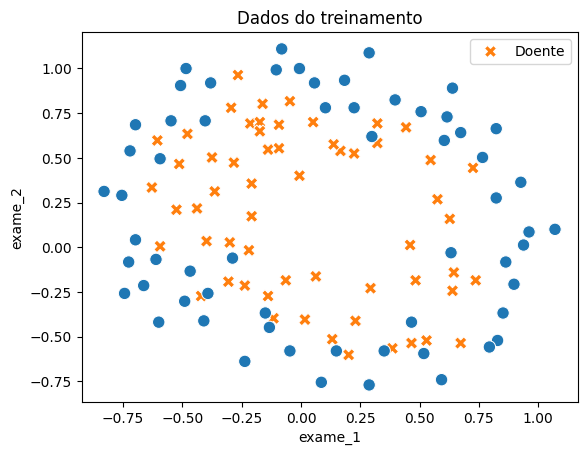

In [ ]:
ax = sns.scatterplot(x='exame_1', y='exame_2', hue='classe', data=df, style='classe', s=80)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[1:], ['Doente', 'Saudável'])
plt.title('Dados do treinamento')
plt.show(ax)

# Exercício

1. (**2.5 pontos**) Encontre uma superfície de decisão que separe as duas classes. Combine as ideias e os códigos dessa aula com os da aula anterior para escrever um modelo não-linear de classificação.  